# Queda não livre — **Euler explícito** vs. solução analítica (arrasto linear)

Modelo: $\dfrac{dv}{dt} = g - \dfrac{b}{m}v$, com $v>0$ para baixo.

- **Numérico (Euler explícito):**
  $$ v_{n+1} = v_n + h\left(g - \frac{b}{m}v_n\right) $$
- **Analítico:**
  $$ v(t) = v_\infty + (v_0 - v_\infty) e^{-t/\tau},\quad v_\infty=\frac{mg}{b},\; \tau=\frac{m}{b}. $$

Abaixo comparamos as duas curvas usando apenas `numpy` e `matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


## Parâmetros
Ajuste à vontade:

In [2]:
m = 80.0       # kg
b = 60.0       # N*s/m
g = 9.81       # m/s^2 (positivo para baixo)
v0 = 0.0       # m/s
t_max = 20.0   # s
n_points = 500 # número de pontos (define h)


## Funções auxiliares

In [3]:
def velocity_linear_drag_analytical(t, m, b, g, v0):
    """Analytical solution for dv/dt = g - (b/m)*v (linear drag).
    Returns v(t) as numpy array.
    """
    tau = m / b
    v_inf = (m * g) / b
    return v_inf + (v0 - v_inf) * np.exp(-t / tau)

def euler_velocity(t, m, b, g, v0):
    """Forward Euler for dv/dt = g - (b/m)*v over the grid t.
    Returns v array the same size as t.
    """
    v = np.zeros_like(t)
    v[0] = v0
    # uniform step assuming t is linspace
    if t.size > 1:
        h = t[1] - t[0]
    else:
        h = 0.0
    # iterate
    for n in range(0, t.size - 1):
        rhs = g - (b / m) * v[n]
        v[n + 1] = v[n] + h * rhs
    return v


Max abs error: 0.07324441007233062


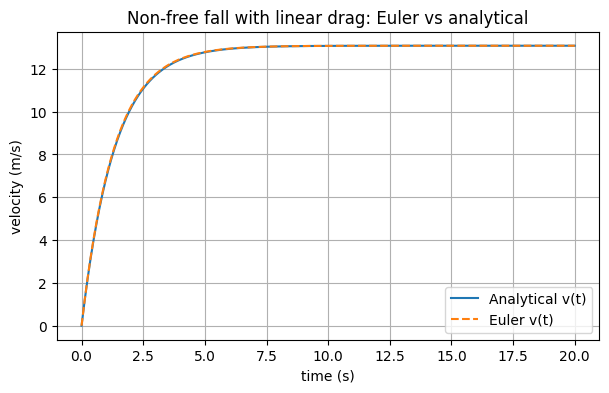

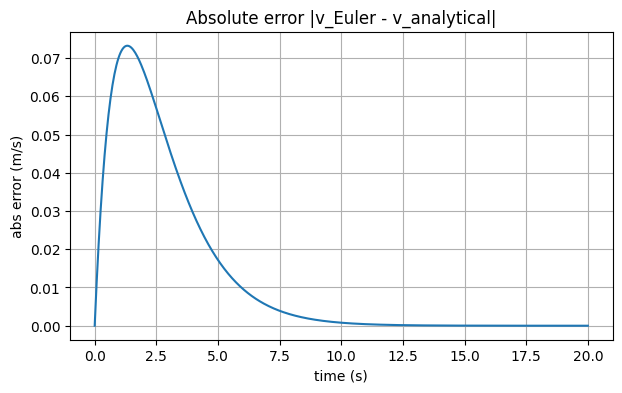

In [4]:
# Malha temporal
t = np.linspace(0.0, t_max, n_points)

# Soluções
v_euler = euler_velocity(t, m, b, g, v0)
v_an = velocity_linear_drag_analytical(t, m, b, g, v0)

# Métrica simples de erro
abs_err = np.abs(v_euler - v_an)
max_abs_err = np.max(abs_err)
print('Max abs error:', float(max_abs_err))

# Plot v(t)
plt.figure(figsize=(7,4))
plt.plot(t, v_an, label='Analytical v(t)')
plt.plot(t, v_euler, label='Euler v(t)', linestyle='--')
plt.xlabel('time (s)')
plt.ylabel('velocity (m/s)')
plt.title('Non-free fall with linear drag: Euler vs analytical')
plt.legend()
plt.grid(True)
plt.show()

# Plot erro absoluto
plt.figure(figsize=(7,4))
plt.plot(t, abs_err)
plt.xlabel('time (s)')
plt.ylabel('abs error (m/s)')
plt.title('Absolute error |v_Euler - v_analytical|')
plt.grid(True)
plt.show()


### Dicas
- Passos menores (maior `n_points`) diminuem o erro do Euler.
- Para arrasto **quadrático**, a EDO muda e a solução analítica é diferente; o Euler segue análogo com a nova RHS.